<a href="https://colab.research.google.com/github/sashwatchauhan27/AI_Zoom_OUT_Generator/blob/main/AI_Zoom_Out_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎨 AI Zoom-Out Generator: Infinite Image Outpainting & Seamless Video Generation
### Academic Project | 2nd-Year Computer Science & AI Engineering
**Author:** College Demonstration  
**Model:** `stable-diffusion-v1-5/stable-diffusion-inpainting` (Hugging Face)  
**Architecture:** Hybrid Cloud-Edge Computing (Local Laptop UI + Google Colab T4 GPU Backend)

---

### 📌 Project Objective:
This project generates a cinematic, continuous "infinite zoom-out" video effect from any single user-uploaded image.
1. The original image is rescaled and placed in the center of an expanded canvas.
2. An automatic inpainting mask isolates the newly added outer borders.
3. Stable Diffusion Inpainting generates contextually coherent surroundings based on user text prompts.
4. The process is iteratively repeated for multiple zoom steps ($k = 1, 2, 3...$).
5. Successive keyframes are mathematically interpolated using cubic easing to synthesize a smooth 24/30 FPS MP4 video.


---
## Section 1: GPU Availability & Hardware Diagnostic
In this section, we verify that Google Colab has allocated an NVIDIA GPU (such as Tesla T4, V100, or A100).
- If `torch.cuda.is_available()` is `False`, switch your Colab runtime: **Runtime -> Change runtime type -> T4 GPU**.


In [14]:
# Hardware Diagnostic & GPU Verification
import os
import sys
import torch

print("=" * 60)
print("SYSTEM HARDWARE DIAGNOSTIC")
print("=" * 60)
print(f"Python Version: {sys.version.split()[0]}")
print(f"PyTorch Version: {torch.__version__}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_count = torch.cuda.device_count()
    vram_bytes = torch.cuda.get_device_properties(0).total_memory
    vram_gb = vram_bytes / (1024 ** 3)
    print(f"✅ NVIDIA GPU DETECTED: {gpu_name}")
    print(f"✅ Device Count: {gpu_count}")
    print(f"✅ Total Dedicated VRAM: {vram_gb:.2f} GB")
    print(f"✅ CUDA Capability: {torch.cuda.get_device_capability(0)}")
else:
    print("⚠️ WARNING: No NVIDIA GPU detected!")
    print("Please go to 'Runtime' -> 'Change runtime type' -> Select 'T4 GPU' to enable AI acceleration.")
print("=" * 60)


SYSTEM HARDWARE DIAGNOSTIC
Python Version: 3.13.16
PyTorch Version: 2.14.1+cu130
✅ NVIDIA GPU DETECTED: Tesla T4
✅ Device Count: 1
✅ Total Dedicated VRAM: 14.56 GB
✅ CUDA Capability: (7, 5)


---
## Section 2: Dependency Installation
We install the essential deep learning, computer vision, and frontend libraries:
- `diffusers`: Hugging Face state-of-the-art diffusion pipeline.
- `transformers`: Hugging Face CLIP text encoders and tokenizers.
- `accelerate`: PyTorch hardware acceleration and memory optimization.
- `gradio` & `gradio_client`: Modern web interface with public share link.
- `opencv-python`, `pillow`, `imageio`, `imageio-ffmpeg`: Image and video synthesis.


!pip install -q diffusers transformers accelerate gradio gradio_client opencv-python pillow imageio imageio-ffmpeg

---
## Section 3: Configuration & Hyperparameters
We configure the default parameters for 2nd-year college demonstration.
These values balance speed, memory safety, and visual quality.


In [15]:
# Configuration Parameters
from pathlib import Path

# Paths
OUTPUT_DIR = Path("outputs")
FRAMES_DIR = OUTPUT_DIR / "frames"
VIDEOS_DIR = OUTPUT_DIR / "videos"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FRAMES_DIR.mkdir(parents=True, exist_ok=True)
VIDEOS_DIR.mkdir(parents=True, exist_ok=True)

# Pre-trained Model ID
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-inpainting"

# Generation Hyperparameters
IMAGE_RESOLUTION = (512, 512)   # Native SD 1.5 latent resolution
DEFAULT_ZOOM_STEPS = 3           # Number of outpainting iterations
DEFAULT_ZOOM_FACTOR = 1.2        # Scale factor per step
DEFAULT_INFERENCE_STEPS = 20     # Diffusion denoising steps
DEFAULT_GUIDANCE_SCALE = 7.5     # Classifier-Free Guidance (CFG)
DEFAULT_VIDEO_FPS = 24           # Video framerate
FRAMES_PER_ZOOM_STEP = 36        # Frames per transition (1.5 seconds per step)

# Default Prompts
DEFAULT_PROMPT = "high resolution, detailed surrounding environment, seamless background, photorealistic, 8k"
DEFAULT_NEGATIVE_PROMPT = (
    "low quality, blurry, distorted, harsh seams, pixelated, artifacts, bad anatomy, "
    "cropped, worst quality, duplicate, text, watermark"
)

print(f"✅ Configuration initialized! Model target: {MODEL_ID}")


✅ Configuration initialized! Model target: stable-diffusion-v1-5/stable-diffusion-inpainting


---
## Section 4: Loading Stable Diffusion Inpainting Pipeline
We load the pre-trained diffusion model `stable-diffusion-v1-5/stable-diffusion-inpainting`.
- We use **`torch.float16`** precision: reduces VRAM from ~8 GB to ~3.5 GB.
- We enable **`pipe.enable_attention_slicing()`**: cuts peak VRAM consumption so memory errors never occur on free Google Colab T4 GPUs.


In [16]:
# Load Pre-Trained Stable Diffusion Inpainting Pipeline
import torch
from diffusers import StableDiffusionInpaintPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
torch_dtype = torch.float16 if device == "cuda" else torch.float32

print(f"Loading {MODEL_ID} on {device} (precision: {torch_dtype})...")

pipe = StableDiffusionInpaintPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=torch_dtype,
    safety_checker=None  # Disable safety checker to conserve VRAM during demo
)
pipe = pipe.to(device)

if device == "cuda":
    pipe.enable_attention_slicing()
    try:
        pipe.enable_vae_slicing()
    except Exception:
        pass

print("✅ Stable Diffusion Inpainting Pipeline loaded and ready for inference!")


Loading stable-diffusion-v1-5/stable-diffusion-inpainting on cuda (precision: torch.float16)...


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--stable-diffusion-v1-5--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
You have disab

✅ Stable Diffusion Inpainting Pipeline loaded and ready for inference!


---
## Section 5: Canvas Expansion & Inpainting Mask Logic
Here we implement the core mathematical logic for outpainting:
1. **Shrink & Center:** The existing image is scaled down by `zoom_factor` (e.g. $1.2$) to dimensions $(W_{inner}, H_{inner})$ and pasted at the center of a $512 \times 512$ canvas.
2. **Context Padding:** The outer borders of the canvas are initialized with a softly blurred expansion of the image so that the VAE encoder receives consistent color palettes.
3. **Inpainting Mask:** An 8-bit grayscale mask is synthesized:
   - **Black (0):** The inner rectangle preserving the user's original image.
   - **White (255):** The border region to be outpainted by Stable Diffusion.
   - A 4-pixel border feathering prevents hard boundary seams.


In [17]:
# Canvas Expansion & Mask Synthesis
from PIL import Image, ImageFilter, ImageDraw
from typing import Tuple

def prepare_canvas_and_mask(
    image: Image.Image,
    zoom_factor: float = 1.2,
    target_size: Tuple[int, int] = (512, 512),
    feather_radius: int = 4
) -> Tuple[Image.Image, Image.Image, Tuple[int, int, int, int]]:
    target_w, target_h = target_size

    # Calculate inner dimensions (multiples of 8 for latent VAE)
    inner_w = max(16, int(round(target_w / zoom_factor)))
    inner_h = max(16, int(round(target_h / zoom_factor)))
    inner_w -= (inner_w % 8)
    inner_h -= (inner_h % 8)

    offset_x = (target_w - inner_w) // 2
    offset_y = (target_h - inner_h) // 2

    shrunk_image = image.resize((inner_w, inner_h), Image.Resampling.LANCZOS)

    # Background canvas: stretched + blurred version provides realistic color bias
    canvas = shrunk_image.resize((target_w, target_h), Image.Resampling.BILINEAR)
    canvas = canvas.filter(ImageFilter.GaussianBlur(radius=15))
    canvas.paste(shrunk_image, (offset_x, offset_y))

    # Mask: 255 (white) = inpaint border, 0 (black) = keep center
    mask = Image.new("L", (target_w, target_h), 255)
    draw = ImageDraw.Draw(mask)
    inset = 4
    draw.rectangle(
        [
            offset_x + inset,
            offset_y + inset,
            offset_x + inner_w - inset,
            offset_y + inner_h - inset
        ],
        fill=0
    )

    if feather_radius > 0:
        mask = mask.filter(ImageFilter.GaussianBlur(radius=feather_radius))

    bbox = (offset_x, offset_y, inner_w, inner_h)
    return canvas, mask, bbox

print("✅ prepare_canvas_and_mask function defined successfully!")


✅ prepare_canvas_and_mask function defined successfully!


---
## Section 6: Image Input / Demo Sample Generation
You can upload your own image using the Colab file upload widget, or use this built-in sample synthetic image (a vibrant futuristic mountain landscape) for testing.


✅ Demo test image created and saved to outputs/sample_input.png!


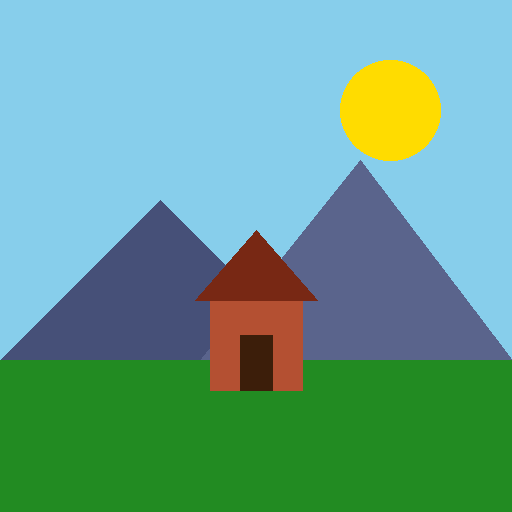

In [18]:
# Create or Upload Input Image
from PIL import Image, ImageDraw
import numpy as np

def create_sample_demo_image():
    """Generates an artistic test landscape with a central subject for demonstration."""
    img = Image.new("RGB", (512, 512), (135, 206, 235)) # Sky
    draw = ImageDraw.Draw(img)

    # Sun
    draw.ellipse([340, 60, 440, 160], fill=(255, 220, 0))
    # Distant Mountains
    draw.polygon([(0, 360), (160, 200), (320, 360)], fill=(70, 80, 120))
    draw.polygon([(200, 360), (360, 160), (512, 360)], fill=(90, 100, 140))
    # Fore ground
    draw.rectangle([0, 360, 512, 512], fill=(34, 139, 34))
    # Central cottage/temple subject
    draw.rectangle([210, 300, 302, 390], fill=(180, 80, 50))
    draw.polygon([(195, 300), (256, 230), (317, 300)], fill=(120, 40, 20))
    draw.rectangle([240, 335, 272, 390], fill=(60, 30, 10))
    return img

# Set up test image
sample_image = create_sample_demo_image()
sample_image.save("outputs/sample_input.png")
print("✅ Demo test image created and saved to outputs/sample_input.png!")
sample_image


---
## Section 7: Single-Step AI Outpainting Test
We run a single outpainting step on the test image.
Observe how the canvas is expanded, the mask is applied, and Stable Diffusion seamlessly synthesizes the outer border!


Running single-step AI outpainting...


  0%|          | 0/20 [00:00<?, ?it/s]

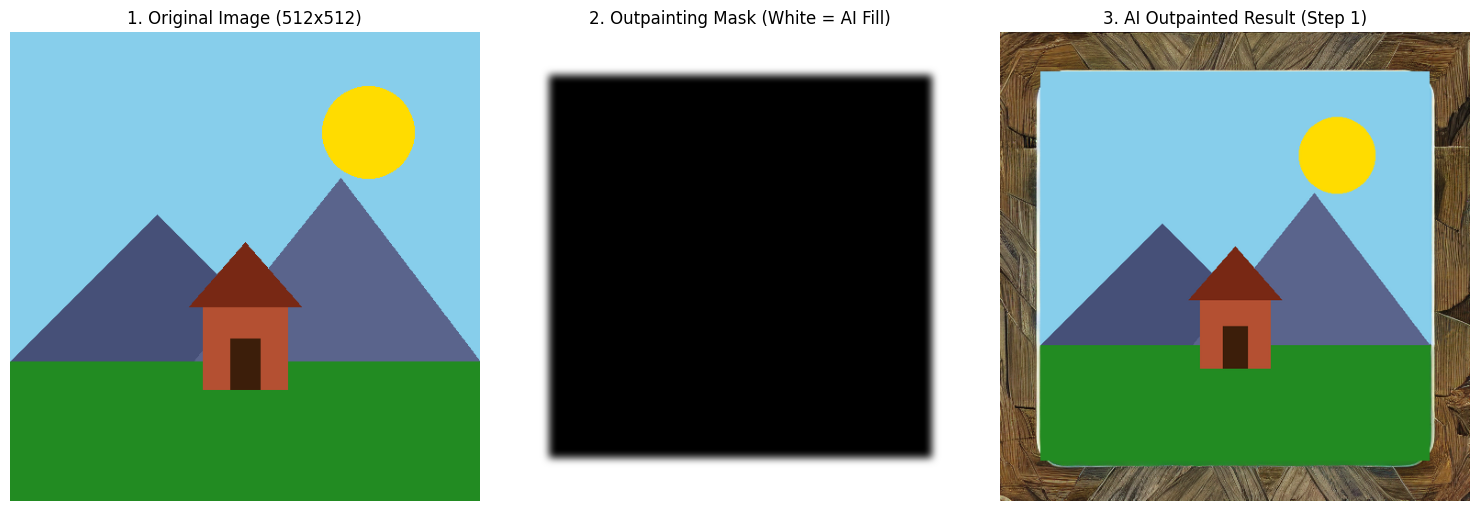

✅ Single-step outpainting executed successfully!


In [19]:
# Run Single Outpainting Step
import matplotlib.pyplot as plt

prompt = "lush scenic alpine valley, realistic pine trees, majestic snowy peaks, 8k photorealistic"
negative_prompt = "low quality, blurry, distorted seams, text, watermark"
seed = 42

print("Running single-step AI outpainting...")
canvas, mask, bbox = prepare_canvas_and_mask(sample_image, zoom_factor=1.2)

generator = torch.Generator(device=device).manual_seed(seed)

with torch.inference_mode():
    output = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=canvas,
        mask_image=mask,
        num_inference_steps=20,
        guidance_scale=7.5,
        generator=generator
    )

single_step_result = output.images[0]

# Preserve original centered image
ox, oy, iw, ih = bbox
shrunk_orig = sample_image.resize((iw, ih), Image.Resampling.LANCZOS)
single_step_result.paste(shrunk_orig, (ox, oy))

# Display comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_image)
axes[0].set_title("1. Original Image (512x512)")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("2. Outpainting Mask (White = AI Fill)")
axes[1].axis("off")

axes[2].imshow(single_step_result)
axes[2].set_title("3. AI Outpainted Result (Step 1)")
axes[2].axis("off")

plt.tight_layout()
plt.show()
print("✅ Single-step outpainting executed successfully!")


---
## Section 8: Multi-Step Iterative Zoom-Out Generation
In this section, we iteratively repeat the outpainting expansion for $N$ zoom steps (e.g., 3 steps).
Each iteration:
- Shrinks the previous step's output.
- Generates new outer context.
- Preserves the central image hierarchy.


In [20]:
# Multi-Step Iterative Outpainting
import time

def run_multi_step_zoom(
    base_image: Image.Image,
    prompt: str = DEFAULT_PROMPT,
    negative_prompt: str = DEFAULT_NEGATIVE_PROMPT,
    zoom_steps: int = 3,
    zoom_factor: float = 1.2,
    num_inference_steps: int = 20,
    guidance_scale: float = 7.5,
    seed: int = 42
):
    keyframes = [base_image]
    current = base_image

    print(f"Starting {zoom_steps}-step infinite zoom-out generation...")
    start_time = time.time()

    for step in range(1, zoom_steps + 1):
        step_seed = seed + step * 7
        print(f"--> Generating Step {step}/{zoom_steps} (seed={step_seed})...")

        canvas, mask, bbox = prepare_canvas_and_mask(current, zoom_factor=zoom_factor)
        generator = torch.Generator(device=device).manual_seed(step_seed)

        with torch.inference_mode():
            out = pipe(
                prompt=prompt,
                negative_prompt=negative_prompt,
                image=canvas,
                mask_image=mask,
                num_inference_steps=num_inference_steps,
                guidance_scale=guidance_scale,
                generator=generator
            )

        generated_frame = out.images[0]

        # Paste original center
        ox, oy, iw, ih = bbox
        shrunk_orig = current.resize((iw, ih), Image.Resampling.LANCZOS)
        generated_frame.paste(shrunk_orig, (ox, oy))

        # Save frame
        frame_path = FRAMES_DIR / f"colab_step_{step:02d}.png"
        generated_frame.save(frame_path)

        keyframes.append(generated_frame)
        current = generated_frame

    elapsed = time.time() - start_time
    print(f"✅ Generated {zoom_steps} keyframes in {elapsed:.1f}s ({elapsed/zoom_steps:.1f}s per step)!")
    return keyframes

# Run multi-step generation
generated_keyframes = run_multi_step_zoom(
    base_image=sample_image,
    prompt="lush alpine landscape, distant snowcapped mountain range, dramatic cinematic lighting, photorealistic 8k",
    negative_prompt=DEFAULT_NEGATIVE_PROMPT,
    zoom_steps=3,
    zoom_factor=1.2,
    num_inference_steps=20
)


Starting 3-step infinite zoom-out generation...
--> Generating Step 1/3 (seed=49)...


  0%|          | 0/20 [00:00<?, ?it/s]

--> Generating Step 2/3 (seed=56)...


  0%|          | 0/20 [00:00<?, ?it/s]

--> Generating Step 3/3 (seed=63)...


  0%|          | 0/20 [00:00<?, ?it/s]

✅ Generated 3 keyframes in 14.7s (4.9s per step)!


---
## Section 9: Smooth MP4 Video Generation
We synthesize a fluid, continuous MP4 zoom-out video from the keyframes using:
- **Cubic Easing:** Simulates natural cinematic camera deceleration and acceleration.
- **Continuous Crop & Rescale:** Smoothly scales from the inner frame to the full outer frame.
- **Cross-Dissolve Blending:** Eliminates boundary discontinuities.
- **Standard H.264 MP4 Encoding:** Plays natively in all web browsers.


In [21]:
# Smooth Video Synthesis & MP4 Export
import math
import cv2
import numpy as np

def ease_in_out_cubic(t: float) -> float:
    return 4.0 * t * t * t if t < 0.5 else 0.5 * (2.0 * t - 2.0) ** 3 + 1.0

def interpolate_zoom(kf_a: Image.Image, kf_b: Image.Image, zoom_factor: float, num_frames: int):
    w, h = kf_b.size
    frames = []
    for idx in range(num_frames):
        raw_t = idx / float(max(1, num_frames - 1))
        t = ease_in_out_cubic(raw_t)
        scale = math.pow(zoom_factor, 1.0 - t)

        cw = max(1.0, w / scale)
        ch = max(1.0, h / scale)
        left = (w - cw) / 2.0
        top = (h - ch) / 2.0

        cropped = kf_b.crop((left, top, left + cw, top + ch))
        rescaled = cropped.resize((w, h), Image.Resampling.BICUBIC)

        if raw_t < 0.25:
            alpha = raw_t / 0.25
            frame = Image.blend(kf_a, rescaled, alpha)
        else:
            frame = rescaled

        frames.append(frame)
    return frames

def build_zoom_video(keyframes, zoom_factor=1.2, fps=24, frames_per_step=36, output_path="outputs/videos/colab_zoomout.mp4"):
    all_frames = []

    # Initial pause (12 frames)
    all_frames.extend([keyframes[0]] * (fps // 2))

    for i in range(len(keyframes) - 1):
        step_frames = interpolate_zoom(keyframes[i], keyframes[i+1], zoom_factor, frames_per_step)
        all_frames.extend(step_frames)

    # Final pause (18 frames)
    all_frames.extend([keyframes[-1]] * int(fps * 0.75))

    # Save video with OpenCV
    w, h = all_frames[0].size
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(output_path, fourcc, float(fps), (w, h))
    for f in all_frames:
        writer.write(cv2.cvtColor(np.array(f), cv2.COLOR_RGB2BGR))
    writer.release()
    print(f"✅ Video successfully created at: {output_path}")
    return output_path

output_video_file = build_zoom_video(generated_keyframes)


✅ Video successfully created at: outputs/videos/colab_zoomout.mp4


---
## Section 10: In-Notebook Video Preview & Download
Preview the generated zoom-out video directly in your Colab notebook or download the MP4 file to your computer.


In [22]:
# Display Video in Colab
from IPython.display import HTML
from base64 import b64encode

def show_video(video_path):
    mp4 = open(video_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    return HTML(f"""
    <video width=512 controls loop autoplay>
        <source src="{data_url}" type="video/mp4">
    </video>
    """)

show_video("outputs/videos/colab_zoomout.mp4")


In [23]:
# Download Generated MP4 Video to Laptop
from google.colab import files
files.download("outputs/videos/colab_zoomout.mp4")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Section 11: Launch Full Interactive Web Application (Gradio Share)
Run the cell below to launch the **Gradio Web Interface** directly inside Google Colab with `share=True`!
- Colab will output a public URL: `https://xxxxxxxx.gradio.live`
- Open that link on your laptop browser to use the full application with Colab GPU acceleration.


In [24]:
# Launch Gradio Web Application with Public Share Link
import gradio as gr

def gradio_pipeline(
    img, prompt, neg_prompt, steps, factor, inf_steps, cfg, seed, fps, frames_per_step
):
    from PIL import Image, ImageOps

    if img is None:
        raise gr.Error("Please upload an image!")

    # Convert any uploaded file into a clean 512x512 RGB image
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img) if hasattr(img, "shape") else Image.open(img)
    img = ImageOps.exif_transpose(img).convert("RGB").resize((512, 512), Image.Resampling.LANCZOS)

    prompt = prompt or DEFAULT_PROMPT
    neg_prompt = neg_prompt or DEFAULT_NEGATIVE_PROMPT
    seed_val = int(seed) if seed is not None and seed >= 0 else 42

    # Run multi-step zoom
    kfs = run_multi_step_zoom(
        base_image=img.convert("RGB"),
        prompt=prompt,
        negative_prompt=neg_prompt,
        zoom_steps=int(steps),
        zoom_factor=float(factor),
        num_inference_steps=int(inf_steps),
        guidance_scale=float(cfg),
        seed=seed_val
    )

    # Build video
    vpath = "outputs/videos/web_zoomout.mp4"
    build_zoom_video(
        keyframes=kfs,
        zoom_factor=float(factor),
        fps=int(fps),
        frames_per_step=int(frames_per_step),
        output_path=vpath
    )

    gallery = [(kf, f"Step {i}") for i, kf in enumerate(kfs)]
    return vpath, gallery, vpath, "Generation complete!"

with gr.Blocks(title="AI Zoom-Out Generator (Colab GPU)") as colab_app:
    gr.Markdown("# 🚀 AI Zoom-Out Generator (Google Colab GPU Worker)")
    with gr.Row():
        with gr.Column():
            in_img = gr.Image(label="Input Image", type="pil")
            p_in = gr.Textbox(label="Prompt", value=DEFAULT_PROMPT)
            np_in = gr.Textbox(label="Negative Prompt", value=DEFAULT_NEGATIVE_PROMPT)
            with gr.Row():
                st_slider = gr.Slider(1, 5, value=3, step=1, label="Zoom Steps")
                zf_slider = gr.Slider(1.1, 1.5, value=1.2, step=0.05, label="Zoom Factor")
            with gr.Row():
                inf_slider = gr.Slider(10, 40, value=20, step=5, label="Inference Steps")
                cfg_slider = gr.Slider(1.0, 15.0, value=7.5, step=0.5, label="CFG Scale")
            seed_in = gr.Number(label="Seed", value=42)
            btn = gr.Button("🚀 Generate Zoom-Out Video", variant="primary")
        with gr.Column():
            v_out = gr.Video(label="Generated Zoom-Out Video", autoplay=True, loop=True)
            f_out = gr.File(label="Download MP4")
            g_out = gr.Gallery(label="Keyframes", columns=3)
            stat = gr.Textbox(label="Status")

    btn.click(
        fn=gradio_pipeline,
        inputs=[in_img, p_in, np_in, st_slider, zf_slider, inf_slider, cfg_slider, seed_in, gr.Number(value=24, visible=False), gr.Number(value=36, visible=False)],
        outputs=[v_out, g_out, f_out, stat]
    )

# Launch with share=True for public access from laptop!
colab_app.queue().launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9ef9ee1a1bbdf5fa91.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
## Section 12: Troubleshooting & Memory Tips

1. **CUDA Out of Memory (OOM):**
   - Reduce image resolution to $512 \times 512$.
   - Reduce inference steps from 30 to 15-20.
   - Run `torch.cuda.empty_cache()` to free unused GPU blocks.

2. **Gradio Share Link Expired:**
   - Free Gradio share links last for 72 hours.
   - Simply re-run the final cell to generate a fresh link.

3. **Colab Disconnection:**
   - Free Colab instances disconnect after ~90 minutes of inactivity. Keep the browser tab open while running long sequences.
